# 02 · Model diagnostics

Diagnostics for the outcome models behind the simulator, fit on 2016–2022 and checked on 2023 validation.

Reads the saved results in `reports/` (`make model`, `make leakage`, `make sim`) and refits the Y1 models for subgroup calibration (needs `data/processed/`). Test-season rows are never loaded.

In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run from the repository root so the relative paths in configs/ and the manifest resolve.
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path("src").resolve()))
pd.set_option("display.width", 120, "display.max_columns", 20, "display.precision", 4)

from bullpen.config import Config
from bullpen.model_y1 import TARGET, fit_all, load, predict_all

## Y1 model ladder on 2023

M0: empirical rate by base-out state. M1: logistic regression on game state only. M2: M1 plus pitcher quality and usage. Intervals are 95% game-clustered bootstrap intervals.

In [2]:
y1 = json.loads(Path("reports/y1/metrics.json").read_text())["results"]
def ladder(key):
    r = y1[key]["models"]
    return pd.DataFrame({n: {"log loss": m["log_loss"], "Brier": m["brier"], "cal. intercept": m["cal_intercept"],
                             "cal. slope": m["cal_slope"], "ECE": m["ece"]} for n, m in r.items()}).T
pd.concat({"all relief states": ladder("validation_all_relief"),
           "decision points": ladder("validation_decision_points")})

log loss   Brier  cal. intercept  cal. slope     ECE
all relief states M0    0.5176  0.1709          0.0144      0.9946  0.0036
                  M1    0.5170  0.1707          0.0308      0.9955  0.0057
                  M2    0.5165  0.1705          0.0420      0.9985  0.0076
decision points   M0    0.5610  0.1876         -0.0764      0.9492  0.0151
                  M1    0.5602  0.1873         -0.0138      0.9484  0.0128
                  M2    0.5599  0.1872          0.0142      0.9431  0.0120

In [3]:
pd.DataFrame({(k, c): {"Δ log loss": d["log_loss_diff"], "CI low": d["ci"][0], "CI high": d["ci"][1]}
              for k in ("validation_all_relief", "validation_decision_points")
              for c, d in y1[k]["differences"].items()}).T

Δ log loss  CI low  CI high
validation_all_relief      M1-M0     -0.0006 -0.0011  -0.0001
                           M2-M1     -0.0005 -0.0009  -0.0001
validation_decision_points M1-M0     -0.0008 -0.0017   0.0001
                           M2-M1     -0.0003 -0.0010   0.0005

Pitcher features improve log loss over the game-state baseline across all 2023 relief states; on the 6,908 decision points alone the improvement cannot be distinguished from zero.

## Reliability

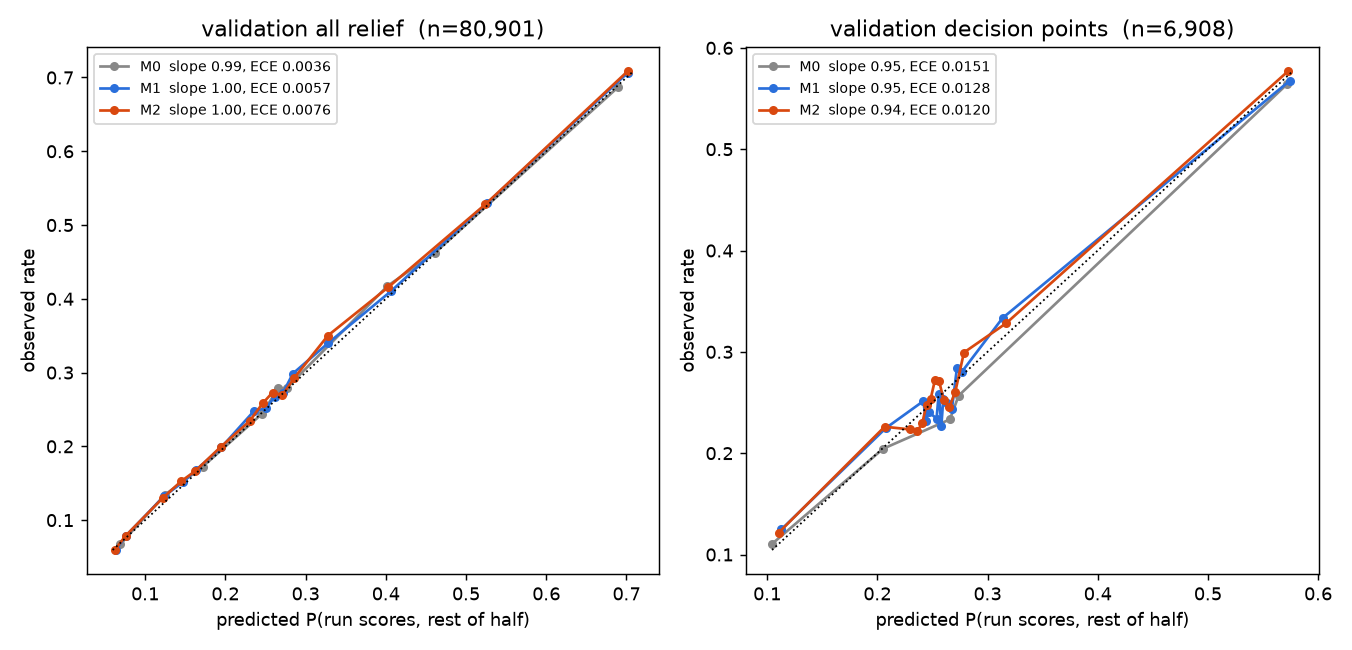

In [4]:
from IPython.display import Image
Image("reports/figures/y1_reliability.png", width=850)

## Calibration-in-the-large by subgroup (refit)

Mean predicted vs observed Y1 on 2023 relief states. Rule-change drift appears as observed > predicted across most groups, not in one corner of the state space.

In [5]:
cfg = Config.from_json("configs/default.json")
states, _ = load(cfg)
train, val = states[states["split"] == "train"], states[states["split"] == "validation"].copy()
m0, models = fit_all(train)
val["p_M2"] = predict_all(val, m0, models)["M2"]
val["inning_group"] = np.where(val["inning"] >= 10, "10+", np.where(val["inning"] >= 7, "7-9", "1-6"))
val["margin_group"] = pd.cut(val["fld_margin"], [-99, -3, -1, 0, 2, 99],
                             labels=["trail 3+", "trail 1-2", "tied", "lead 1-2", "lead 3+"])
val["outs"] = val["state24"].str[0]
def calib(col):
    g = val.groupby(col, observed=True)
    return pd.DataFrame({"n": g.size(), "observed": g[TARGET].mean(), "predicted M2": g["p_M2"].mean()}) \
             .assign(gap=lambda d: d["observed"] - d["predicted M2"])
pd.concat({c: calib(c) for c in ["inning_group", "margin_group", "outs"]}).round(4)

n  observed  predicted M2     gap
inning_group 1-6        22604    0.2838        0.2797  0.0041
             10+         2386    0.4426        0.4383  0.0043
             7-9        55911    0.2634        0.2550  0.0084
margin_group trail 3+   22162    0.2911        0.2820  0.0090
             trail 1-2  15860    0.2763        0.2701  0.0062
             tied       10688    0.3010        0.2939  0.0071
             lead 1-2   15135    0.2544        0.2502  0.0042
             lead 3+    17056    0.2521        0.2441  0.0080
outs         0          26252    0.3684        0.3616  0.0068
             1          26995    0.3017        0.2926  0.0091
             2          27654    0.1585        0.1531  0.0054

## M2 coefficients (non-game-state)

Odds ratios per unit. Usage coefficients are associations shaped by manager choices (tired relievers are used when they look fine), not causal fatigue effects.

In [6]:
coef = pd.read_csv("reports/y1/coefficients.csv")
coef[(coef["model"] == "M2") & coef["feature"].str.startswith("num__")] \
    .assign(feature=lambda d: d["feature"].str.removeprefix("num__"))[["feature", "odds_ratio_per_unit", "coef_std"]] \
    .set_index("feature").round(4)

,odds_ratio_per_unit,coef_std
feature,,
fld_is_home,0.9331,-0.0346
extra_runner_era,0.9667,-0.0165
pitcher_runs_saved_per100,0.9521,-0.0588
log_rating_eff_bf,0.9688,-0.0350
pitched_d1,0.9726,-0.0100
pitched_d2,1.0291,0.0126
bf_d1,1.0140,0.0199
apps_prev4,1.0003,0.0003
pitcher_bf_in_game,1.0064,0.0165


## Leakage checks

Each check recomputes a feature, parameter or target independently of the build code.

In [7]:
leak = json.loads(Path("reports/y1/leakage.json").read_text())
pd.DataFrame({k: {"pass": v["pass"], "detail": {a: b for a, b in v.items() if a != "pass"}} for k, v in leak.items()}).T

,pass,detail
no_outcome_columns_in_features,True,{'overlap': []}
splits_disjoint_by_game,True,"{'games_by_split': {'train': 15473, 'warmup': ..."
re_matrix_fit_on_train_only,True,"{'max_diff_vs_train': 0.0, 'max_diff_if_valida..."
rating_mu_fit_on_train_only,True,"{'mu_recomputed': -0.005662807902679661, 'mu_s..."
ratings_use_only_earlier_dates,True,"{'n': 3000, 'max_abs_diff': 2.0816681711721685..."
usage_uses_only_earlier_days,True,"{'n': 3000, 'mismatches': {'pitched_d1': 0, 'p..."
bf_in_game_counts_only_earlier_events,True,{'mismatches': 0}
target_is_runs_from_this_event_to_end_of_half,True,{'n': 3000}


## Run-distribution model (Y1b) and simulator self-consistency

The simulator draws runs per half-inning from the Y1b model (0 / 1 / 2 / 3+ runs). Self-consistency simulates each team's actual choice at 2023 decision points and compares the predicted win probability with realised wins.

,log loss
M0,0.7948
M1,0.7934
M2,0.7930


log loss  cal. intercept  cal. slope
recal    WE0_table     0.4726          0.0003      0.9477
         SIM_actual    0.4669         -0.0234      0.9849
no_recal WE0_table     0.4726          0.0003      0.9477
         SIM_actual    0.4669         -0.0325      0.9718

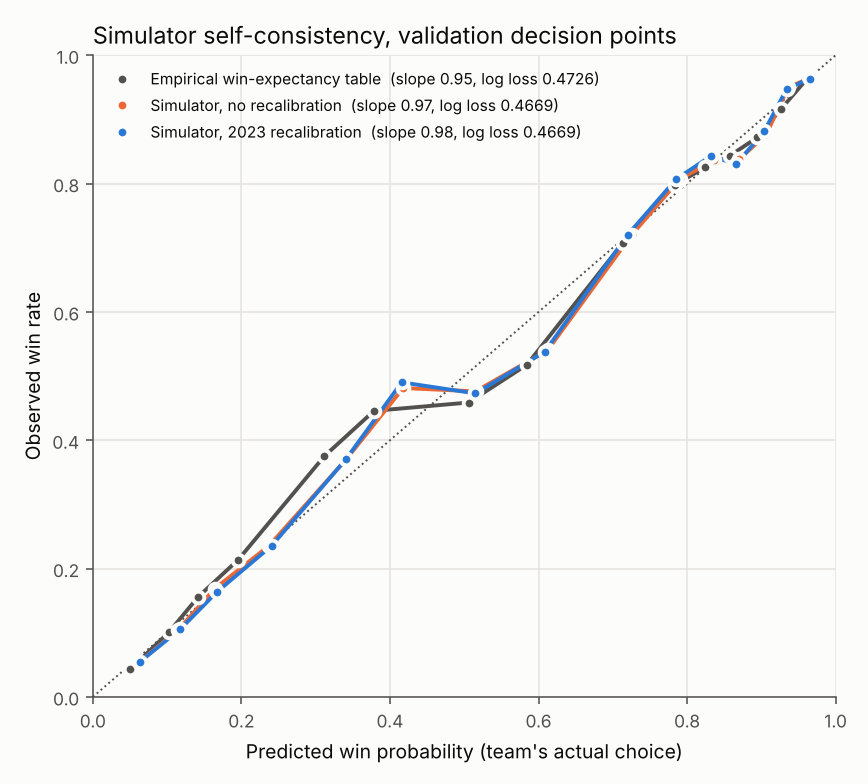

In [8]:
sim = json.loads(Path("reports/sim/metrics_validation.json").read_text())
y1b = pd.DataFrame({n: {"log loss": m["log_loss"]} for n, m in sim["y1b_ladder"]["models"].items()}).T
sc = pd.DataFrame({(tag, n): {"log loss": m["log_loss"], "cal. intercept": m["cal_intercept"], "cal. slope": m["cal_slope"]}
                   for tag, r in sim["self_consistency"].items() for n, m in r["models"].items()}).T
display(y1b.round(4), sc.round(4))
Image("reports/figures/sim_win_calibration.png", width=600)

## Assumption tests for the strategy comparison

Mean ΔWP = P(win | best reliever now) − P(win | save him), in percentage points, with game-resampling intervals.

In [9]:
rows = {"primary": sim["dwp"]["overall"], **sim["sensitivity"]}
pd.DataFrame({k: {"n": v["n"], "mean ΔWP (pp)": 100 * v["mean"], "CI low": 100 * v["ci"][0],
                  "CI high": 100 * v["ci"][1]} for k, v in rows.items()}).T.round(3)

,n,mean ΔWP (pp),CI low,CI high
primary,6908.0,0.112,0.103,0.120
recalibration: no_recal,6908.0,0.105,0.096,0.113
reserve rule: save_only,6908.0,0.174,0.163,0.185
reserve rule: late_close,6908.0,0.157,0.146,0.167
training without 2020,6908.0,0.109,0.098,0.118
strong opponent bullpen,6908.0,0.110,0.100,0.119
placebo: no pitcher features (M1),6908.0,0.000,0.000,0.000
availability: strict,6840.0,0.123,0.111,0.133
availability: lenient,6909.0,0.105,0.096,0.115


Every variant keeps the sign and order of magnitude of the primary estimate; the placebo without pitcher features is exactly zero, as it must be when the two strategies differ only in which pitcher is used.